# **Universidad de Buenos Aires**
# CEIA - Aprendizaje por Refuerzo I
# Tema: Monte Carlo Off-Policy con Importance Sampling (MCIS) en FrozenLake
---
# Trabajo Práctico 1

De acuerdo a la siguiente celda:
1. Resolver y responder las preguntas modificando el código original y reescribiéndolo luego de cada pregunta.
2. **Ejecutar 3 veces** cada celda modificada antes de responder cada pregunta.

Ep 5000 | ε=0.082 | Reward medio (últ. 1k): 0.308


Ep 10000 | ε=0.010 | Reward medio (últ. 1k): 0.572


Ep 15000 | ε=0.010 | Reward medio (últ. 1k): 0.630


Ep 20000 | ε=0.010 | Reward medio (últ. 1k): 0.646


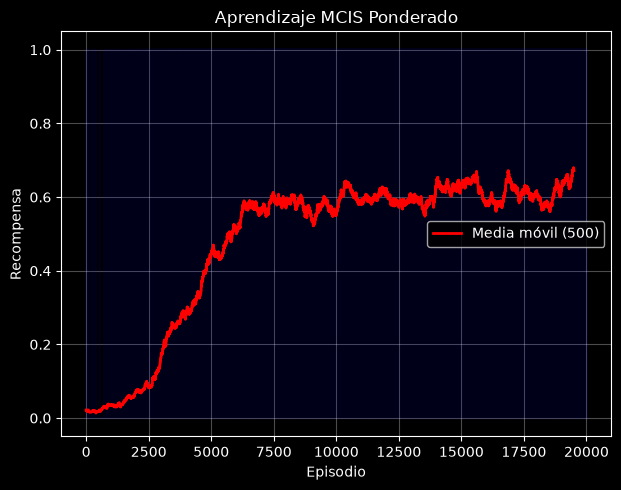


✅ Tasa de éxito de la política aprendida: 69.7%

Política aprendida (← 0, ↓ 1, → 2, ↑ 3):
🤖 ↑ ← ↑ 
← 🕳️ ← 🕳️ 
↑ ↓ ← 🕳️ 
🕳️ → ↓ 🎯 


In [1]:
# ============================================================
# 1: Instalación e imports
# ============================================================
!pip install gymnasium matplotlib numpy -q

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('dark_background')
from collections import defaultdict

np.random.seed(42)

# ============================================================
# 2: Entorno y parámetros
# ============================================================
env = gym.make('FrozenLake-v1', is_slippery=True, map_name="4x4")

NUM_EPISODES = 20000
GAMMA = 1.0
EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.9995

# ============================================================
# 3: Inicialización
# ============================================================

Q = defaultdict(lambda: np.zeros(env.action_space.n))
C = defaultdict(lambda: np.zeros(env.action_space.n))

def greedy_policy(s):
    return int(np.argmax(Q[s]))

def pi_prob(s, a):
    """π(a|s): 1 si es la acción greedy, 0 si no."""
    return 1.0 if a == greedy_policy(s) else 0.0

def mu_prob(s, a, epsilon):
    """Política de comportamiento (ε-greedy)"""
    nA = env.action_space.n
    if a == greedy_policy(s):
        return 1.0 - epsilon + epsilon / nA
    else:
        return epsilon / nA


# ============================================================
# 4: Generación de episodio
# ============================================================
def generate_episode(epsilon):
    episode = []
    state, _ = env.reset()
    while True:
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = greedy_policy(state)

        next_state, reward, terminated, truncated, _ = env.step(action)
        episode.append((state, action, reward))

        if terminated or truncated:
            break
        state = next_state
    return episode

# ============================================================
# 5: Bucle principal MCIS
# ============================================================
rewards_per_episode = []
epsilon = EPSILON_START

for ep in range(NUM_EPISODES):
    episode = generate_episode(epsilon)

    G = 0.0
    W = 1.0

    # Bucle hacia atrás
    for t in range(len(episode) - 1, -1, -1):
        St, At, Rt = episode[t]
        G = GAMMA * G + Rt

        C[St][At] += W
        Q[St][At] += (W / C[St][At]) * (G - Q[St][At])
        W = W * (pi_prob(St, At) / mu_prob(St, At, epsilon))

        if W == 0:
            break

    rewards_per_episode.append(episode[-1][2])
    epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    if (ep + 1) % 5000 == 0:
        avg_last = np.mean(rewards_per_episode[-1000:])
        print(f"Ep {ep+1} | ε={epsilon:.3f} | Reward medio (últ. 1k): {avg_last:.3f}")

# ============================================================
# 6: Visualización
# ============================================================
def moving_average(x, w=500):
    return np.convolve(x, np.ones(w)/w, mode='valid')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(rewards_per_episode, alpha=0.1, color='blue')
plt.plot(moving_average(rewards_per_episode, 500), color='red', linewidth=2, label='Media móvil (500)')
plt.xlabel('Episodio'); plt.ylabel('Recompensa')
plt.title('Aprendizaje MCIS Ponderado')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 7: Evaluación y Política Final
# ============================================================
def evaluate_policy(n_eval=1000):
    successes = 0
    for _ in range(n_eval):
        state, _ = env.reset()
        done = False
        while not done:
            action = greedy_policy(state) # Evaluación 100% Greedy
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            if terminated and reward == 1.0:
                successes += 1
                break
    return successes / n_eval

print(f"\n✅ Tasa de éxito de la política aprendida: {evaluate_policy()*100:.1f}%")

ARROWS = {0: '←', 1: '↓', 2: '→', 3: '↑'}
SPECIAL = {0: '🤖', 5: '🕳️', 7: '🕳️', 11: '🕳️', 12: '🕳️', 15: '🎯'}

print("\nPolítica aprendida (← 0, ↓ 1, → 2, ↑ 3):")
for row in range(4):
    line = ""
    for col in range(4):
        s = row * 4 + col
        if s in SPECIAL:
            line += SPECIAL[s] + " "
        else:
            line += ARROWS[greedy_policy(s)] + " "
    print(line)

## Preparación para resolver las preguntas

Se prefiere la GPU cuando el cálculo es tensorial, pero en este TP no conviene: Q es una tabla de 16 por 4 y gymnasium simula FrozenLake en CPU un paso por vez, de modo que cada decisión greedy es una consulta chica y secuencial. La celda mide esa consulta en los dos dispositivos y la GPU resulta unas 35 veces más lenta, por la latencia de lanzar cada operación y traer el resultado. Lo que sí acelera es correr en paralelo las semillas y configuraciones, que son independientes, en todos los hilos de la CPU con joblib.

Referencia óptima. Para tener un techo con el cual leer las tasas de éxito, la celda calcula también la política óptima por iteración de valor usando el modelo de transiciones de FrozenLake (Programación dinámica, págs. 71 a 73). El agente MCIS no usa ese modelo; la política óptima llega a la meta en el 74.8% de los episodios, de modo que ningún agente puede superar ese valor.

In [2]:
# ============================================================
# Preparación: dispositivo, semillas y utilidades comunes
# ============================================================
import os
import platform
import time
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

try:
    from joblib import Parallel, delayed
except ImportError:
    %pip install joblib -q
    from joblib import Parallel, delayed

plt.style.use('dark_background')


def nombre_cpu():
    """Nombre comercial del procesador (registro en Windows, /proc/cpuinfo en Linux)."""
    try:
        if platform.system() == 'Windows':
            import winreg
            clave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                                   r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
            return winreg.QueryValueEx(clave, 'ProcessorNameString')[0].strip()
        with open('/proc/cpuinfo') as f:
            for linea in f:
                if linea.startswith('model name'):
                    return linea.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or 'CPU'


def nombre_gpu():
    """Nombre de la GPU CUDA, o None si no hay."""
    try:
        import torch
        return torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        return None


def us_por_argmax(argmax, q, n=2000):
    """Microsegundos por consulta greedy sobre una fila de Q."""
    argmax(q)  # calentamiento
    t0 = time.perf_counter()
    for _ in range(n):
        int(argmax(q))
    return (time.perf_counter() - t0) / n * 1e6


# Se prefiere GPU cuando el cálculo es tensorial. En MCIS tabular Q es una tabla
# de 16x4 y gymnasium simula FrozenLake en CPU, un paso por vez: cada decisión
# greedy es una consulta chica y secuencial. Se mide para justificar la elección.
CPU, GPU = nombre_cpu(), nombre_gpu()
N_PROCESOS = os.cpu_count()
print(f"CPU detectada: {CPU} ({N_PROCESOS} hilos)")
print(f"GPU detectada: {GPU or 'ninguna'}")
t_cpu = us_por_argmax(np.argmax, np.zeros(4))
if GPU:
    import torch
    t_gpu = us_por_argmax(torch.argmax, torch.zeros(4, device='cuda'))
    print(f"Consulta greedy sobre una fila de Q: CPU {t_cpu:.1f} µs, GPU {t_gpu:.1f} µs")
print(f"Dispositivo seleccionado: CPU {CPU}, {N_PROCESOS} corridas en paralelo")

SEMILLAS = list(range(42, 72))   # 30 corridas por configuración
N_EJECUCIONES = 3                # las 3 primeras semillas son las 3 ejecuciones pedidas
N_PUNTOS_CURVA = 200             # bloques en que se resume cada curva de entrenamiento
NO_TERMINALES = [0, 1, 2, 3, 4, 6, 8, 9, 10, 13, 14]
ARROWS = {0: '←', 1: '↓', 2: '→', 3: '↑'}
MAPA = ['SFFF', 'FHFH', 'FFFH', 'HFFG']
COLORES = ['#3987e5', '#d95926', '#199e70', '#c98500', '#d55181', '#008300', '#9085e9', '#e66767']


def evaluate_policy(env, Q, n_eval=1000):
    """Sección 7 original (100% greedy); además mide el largo de los episodios
    y la cantidad de pasos de los que llegan a la meta."""
    successes, pasos, pasos_meta = 0, 0, 0
    for _ in range(n_eval):
        state, _ = env.reset()
        done = False
        t = 0
        while not done:
            action = int(np.argmax(Q[state]))
            state, reward, terminated, truncated, _ = env.step(action)
            t += 1
            done = terminated or truncated
            if terminated and reward == 1.0:
                successes += 1
                pasos_meta += t
                break
        pasos += t
    return successes / n_eval, pasos / n_eval, pasos_meta / max(successes, 1)


def resultado_corrida(env, Q, C, rewards_per_episode, epsilon, n_updates, t0, **extra):
    """Lo que cada corrida devuelve al proceso principal."""
    r = np.array(rewards_per_episode, dtype=float)
    exito, largo, pasos_meta = evaluate_policy(env, Q)
    return {
        'exito': exito,
        'largo_eval': largo,
        'pasos_meta': pasos_meta,
        'num_episodes': len(r),
        'curva': r.reshape(N_PUNTOS_CURVA, -1).mean(axis=1),
        'politica': [int(np.argmax(Q[s])) for s in range(16)],
        'eps_final': epsilon,
        'act_por_ep': n_updates / len(r),
        'sin_actualizar': sum(int((C[s] == 0).sum()) for s in NO_TERMINALES),
        'segundos': time.perf_counter() - t0,
        **extra,
    }


def ejecutar(entrenar, configuraciones, semillas=SEMILLAS):
    """Entrena cada configuración con todas las semillas, en paralelo."""
    t0 = time.perf_counter()
    tareas = [(cfg, s) for cfg in configuraciones for s in semillas]
    salidas = Parallel(n_jobs=N_PROCESOS)(delayed(entrenar)(s, **cfg) for cfg, s in tareas)
    n = len(semillas)
    print(f"{len(tareas)} corridas en {time.perf_counter() - t0:.0f} s con {N_PROCESOS} procesos\n")
    return [salidas[i * n:(i + 1) * n] for i in range(len(configuraciones))]


def exitos(res):
    return np.array([r['exito'] for r in res])


def resumir(etiquetas, resultados):
    """Tabla con las 3 ejecuciones pedidas, la media de 30 semillas y diagnósticos."""
    print(f"{'configuración':<34}{'ejec 1':>8}{'ejec 2':>8}{'ejec 3':>8}{'media 3':>9}"
          f"{'media ' + str(len(resultados[0])) + ' ± ee':>16}{'act/ep':>8}{'sin act':>8}{'largo':>7}{'a meta':>8}")
    for et, res in zip(etiquetas, resultados):
        ex = 100 * exitos(res)
        ee = ex.std(ddof=1) / np.sqrt(len(ex))
        tres = ''.join(f"{e:>7.1f}%" for e in ex[:N_EJECUCIONES])
        print(f"{et:<34}{tres}{ex[:N_EJECUCIONES].mean():>8.1f}%{ex.mean():>9.1f}% ± {ee:>4.1f}"
              f"{np.mean([r['act_por_ep'] for r in res]):>8.1f}"
              f"{np.mean([r['sin_actualizar'] for r in res]):>8.1f}"
              f"{np.mean([r['largo_eval'] for r in res]):>7.1f}"
              f"{np.mean([r['pasos_meta'] for r in res if r['exito'] > 0] or [0]):>8.1f}")


def graficar(etiquetas, resultados, titulo):
    """Izquierda: éxito durante el entrenamiento (media de las semillas).
    Derecha: éxito de la política greedy por semilla, 3 ejecuciones y media ± ee."""
    n_sem = len(resultados[0])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    for i, (et, res) in enumerate(zip(etiquetas, resultados)):
        n_ep = res[0]['num_episodes']
        x = (np.arange(N_PUNTOS_CURVA) + 0.5) * n_ep / N_PUNTOS_CURVA
        ax1.plot(x, 100 * np.mean([r['curva'] for r in res], axis=0),
                 color=COLORES[i], linewidth=2, label=et)
        ex = 100 * exitos(res)
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(ex))
        ax2.scatter(i + jitter, ex, s=14, color='#8a8a85', alpha=0.7,
                    label=f'{n_sem} semillas' if i == 0 else None)
        ax2.scatter(np.full(N_EJECUCIONES, i), ex[:N_EJECUCIONES], s=70, facecolors='none',
                    edgecolors='white', linewidths=1.5, label='3 ejecuciones' if i == 0 else None)
        ax2.errorbar(i + 0.3, ex.mean(), yerr=ex.std(ddof=1) / np.sqrt(len(ex)), fmt='D',
                     color=COLORES[i], markersize=8, capsize=4, linewidth=2)
    ax2.plot([], [], 'D', color='white', label='media ± ee (color de la configuración)')
    ax1.set_xlabel('Episodio'); ax1.set_ylabel('Éxito en entrenamiento (%)')
    ax1.set_title(f'{titulo}: aprendizaje (media de {n_sem} semillas)')
    ax1.legend(fontsize=9); ax1.grid(alpha=0.2)
    ax2.set_xticks(range(len(etiquetas)), etiquetas, rotation=20, ha='right', fontsize=9)
    ax2.set_ylabel('Tasa de éxito greedy (%)')
    ax2.set_title(f'{titulo}: evaluación final')
    ax2.legend(fontsize=9); ax2.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


def politica_optima(gamma, env, iteraciones=2000):
    """Iteración de valor con el modelo del entorno (env.unwrapped.P). Solo sirve de
    referencia para comparar: el agente MCIS no conoce el modelo."""
    P = env.unwrapped.P
    V = np.zeros(16)
    for _ in range(iteraciones):
        Qm = np.array([[sum(p * (r + gamma * V[s2] * (not d)) for p, s2, r, d in P[s][a])
                        for a in range(4)] for s in range(16)])
        V = Qm.max(axis=1)
    return [int(a) for a in Qm.argmax(axis=1)]


def evaluar_politica_fija(env, politica, n_eval=10000, semilla=0):
    """Evalúa una política determinista con evaluate_policy (Q one hot por estado),
    siempre sobre la misma secuencia de episodios."""
    env.reset(seed=semilla)
    return evaluate_policy(env, {s: np.eye(4)[politica[s]] for s in range(16)}, n_eval)


def mostrar_politicas(res, titulo):
    """Sección 7 original sin emojis, para las 3 ejecuciones lado a lado (H agujero, G meta)."""
    print(f"\n{titulo} (← 0, ↓ 1, → 2, ↑ 3)")
    print('    '.join(f"ejec {k + 1}: {100 * res[k]['exito']:4.1f}%" for k in range(N_EJECUCIONES)))
    for fila in range(4):
        bloques = []
        for r in res[:N_EJECUCIONES]:
            celdas = [MAPA[fila][c] if MAPA[fila][c] in 'HG' else ARROWS[r['politica'][fila * 4 + c]]
                      for c in range(4)]
            bloques.append(' '.join(celdas).ljust(14))
        print('    '.join(bloques))


# Techo de referencia: política óptima con GAMMA = 1 calculada con el modelo
env_ref = gym.make('FrozenLake-v1', is_slippery=True, map_name="4x4")
POLITICA_OPTIMA = politica_optima(1.0, env_ref)
EXITO_OPTIMO, _, PASOS_OPTIMO = evaluar_politica_fija(env_ref, POLITICA_OPTIMA)
print(f"\nReferencia: la política óptima (iteración de valor con el modelo) llega a la meta "
      f"en el {100 * EXITO_OPTIMO:.1f}% de 10000 episodios, en {PASOS_OPTIMO:.1f} pasos de media")

CPU detectada: Intel(R) Core(TM) i9-14900K (32 hilos)
GPU detectada: NVIDIA GeForce RTX 5080
Consulta greedy sobre una fila de Q: CPU 0.7 µs, GPU 25.2 µs
Dispositivo seleccionado: CPU Intel(R) Core(TM) i9-14900K, 32 corridas en paralelo



Referencia: la política óptima (iteración de valor con el modelo) llega a la meta en el 74.8% de 10000 episodios, en 38.6 pasos de media


**1.** ¿Qué ocurre si se inicializa `Q` en un valor diferente a 0? ¿Por qué? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

Se decidio probar con mas semillas dado que se observo gran variabilidad en los resultados, incluso gran disparidad en la celda de ejemplo que no lo fija. Para esto se toman 30 semillas, luego se presentan las politicas para las 3 pedidas.

210 corridas en 47 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
Q_INIT = 0.0 (original)              69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
Q_INIT = -1.0                         7.5%   22.0%    0.0%     9.8%     23.8% ±  4.1     9.3     0.0   19.0    22.6
Q_INIT = -0.1                         7.5%   22.0%    0.0%     9.8%     23.8% ±  4.1     9.3     0.0   19.0    22.6
Q_INIT = 0.1                         59.9%   12.7%    4.3%    25.6%     26.7% ±  4.0    10.7     0.0   21.6    25.0
Q_INIT = 0.5                         18.3%   12.7%   12.1%    14.4%     31.1% ±  4.3    11.2     0.0   22.5    25.4
Q_INIT = 1.0                         25.1%    6.5%   51.4%    27.7%     39.7% ±  5.0    14.9     0.0   26.8    28.1
Q_INIT = 2.0                         25.1%    6.5%   51.4%    27.7%     39.7% ±  5.0    15.1     0.0   26.7    28.0


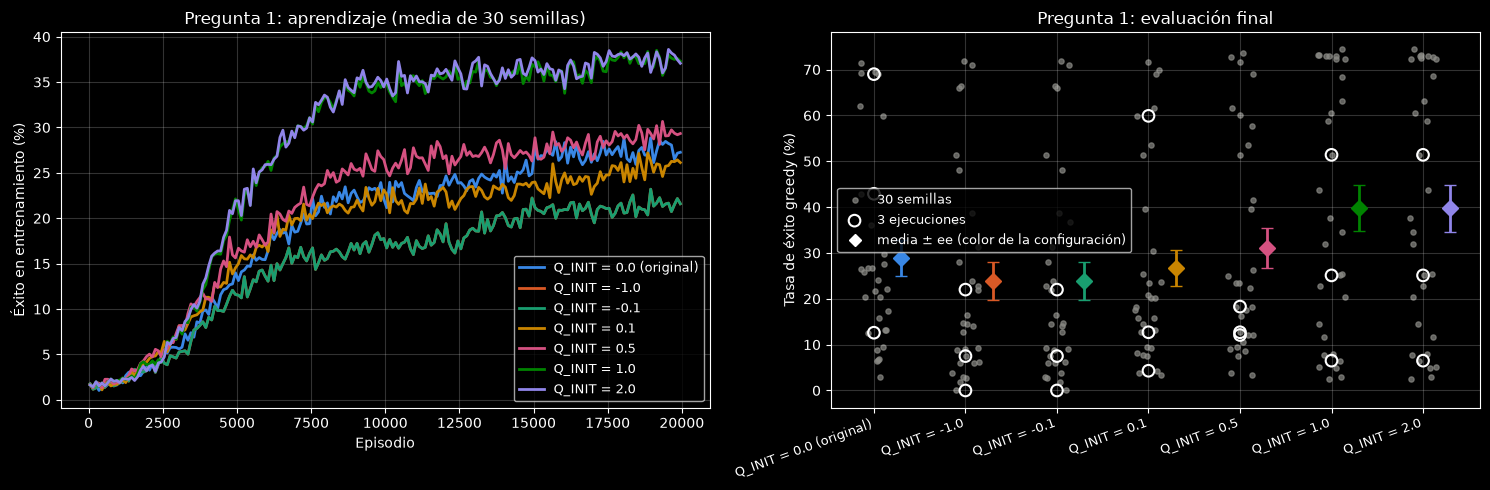


Política aprendida con Q_INIT = 0 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 69.0%    ejec 2: 12.6%    ejec 3: 42.9%
← ← ↑ ↓           ↑ ↑ → ↓           → ↑ ↓ ←       
← H → H           ← H → H           ← H ← H       
↑ ↓ ← H           → ↓ ← H           ↑ ↓ ← H       
H → ↓ G           H → ↓ G           H → ↓ G       

Política aprendida con Q_INIT = 1 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 25.1%    ejec 2:  6.5%    ejec 3: 51.4%
↑ ↑ ← ↑           ← ↑ ↓ ←           → ↑ ← ←       
↓ H ← H           → H ← H           ← H → H       
↑ ↓ ← H           ↑ → ↓ H           ↑ ↓ ← H       
H → ↓ G           H ↑ ↓ G           H → ↓ G       


In [ ]:
# Pregunta 1: El cambio de esta pregunta es Q_INIT, el valor con el que arranca cada Q(s, a).
def entrenar_mcis(semilla, NUM_EPISODES=20000, GAMMA=1.0, EPSILON_START=1.0,
                  EPSILON_END=0.01, EPSILON_DECAY=0.9995, Q_INIT=0.0):
    t0 = time.perf_counter()
    np.random.seed(semilla)
    env = gym.make('FrozenLake-v1', is_slippery=True, map_name="4x4")
    env.reset(seed=semilla)
    env.action_space.seed(semilla)

    Q = defaultdict(lambda: np.full(env.action_space.n, Q_INIT, dtype=float))
    C = defaultdict(lambda: np.zeros(env.action_space.n))

    def greedy_policy(s):
        return int(np.argmax(Q[s]))

    def pi_prob(s, a):
        """π(a|s): 1 si es la acción greedy, 0 si no."""
        return 1.0 if a == greedy_policy(s) else 0.0

    def mu_prob(s, a, epsilon):
        """Política de comportamiento (ε-greedy)"""
        nA = env.action_space.n
        if a == greedy_policy(s):
            return 1.0 - epsilon + epsilon / nA
        else:
            return epsilon / nA

    def generate_episode(epsilon):
        episode = []
        state, _ = env.reset()
        while True:
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
            else:
                action = greedy_policy(state)

            next_state, reward, terminated, truncated, _ = env.step(action)
            episode.append((state, action, reward))

            if terminated or truncated:
                break
            state = next_state
        return episode

    rewards_per_episode = []
    epsilon = EPSILON_START
    n_updates = 0  # diagnóstico: actualizaciones de Q por episodio antes de que W se anule

    for ep in range(NUM_EPISODES):
        episode = generate_episode(epsilon)

        G = 0.0
        W = 1.0

        # Bucle hacia atrás
        for t in range(len(episode) - 1, -1, -1):
            St, At, Rt = episode[t]
            G = GAMMA * G + Rt

            C[St][At] += W
            Q[St][At] += (W / C[St][At]) * (G - Q[St][At])
            n_updates += 1
            W = W * (pi_prob(St, At) / mu_prob(St, At, epsilon))

            if W == 0:
                break

        rewards_per_episode.append(episode[-1][2])
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    return resultado_corrida(env, Q, C, rewards_per_episode, epsilon, n_updates, t0)


VALORES_Q_INIT = [0.0, -1.0, -0.1, 0.1, 0.5, 1.0, 2.0]
etiquetas_p1 = [f"Q_INIT = {v}" + (" (original)" if v == 0 else "") for v in VALORES_Q_INIT]
res_p1 = ejecutar(entrenar_mcis, [dict(Q_INIT=v) for v in VALORES_Q_INIT])
res_base = res_p1[0]  # configuración original, se reutiliza como referencia
resumir(etiquetas_p1, res_p1)
graficar(etiquetas_p1, res_p1, 'Pregunta 1')
mostrar_politicas(res_base, 'Política aprendida con Q_INIT = 0')
mostrar_politicas(res_p1[VALORES_Q_INIT.index(1.0)], 'Política aprendida con Q_INIT = 1')

Respuesta

Con la inicialización original (Q = 0) la tasa de éxito media en 30 semillas es 28.8%. Con valores negativos (−1 y −0.1) baja a 23.8%, con valores positivos menores que 1 (0.1 y 0.5) da 26.7% y 31.1%, y con valores iguales o mayores que 1 (1 y 2) sube a 39.7%. Las diferencias con los valores negativos o intermedios están dentro del error estándar (unos 4 puntos), así que no cambian el resultado; la única mejora es la de Q_INIT ≥ 1, de unos 11 puntos, y es moderada frente a la dispersión entre semillas.

Por qué. En el muestreo por importancia ponderado la primera actualización de un par (s, a) borra el valor inicial: C(s, a) arranca en 0, en la primera visita queda C = W, el paso W/C vale 1 y Q(s, a) pasa a valer exactamente el retorno G. De ahí en adelante Q es un promedio ponderado de retornos y Q_INIT desaparece. Por eso Q_INIT solo actúa a través de los pares que todavía no se actualizaron, y lo único que importa es su posición frente a los retornos posibles, que en FrozenLake son 0 o 1: −1 y −0.1 dan exactamente los mismos resultados en las 30 semillas, y 1 y 2 dan la misma tasa de éxito.

1. Con Q_INIT negativo cualquier acción ya probada (Q ≥ 0) le gana a una no probada, así que la política greedy se aferra a las primeras acciones que actualizó y la exploración depende solo de ε. Las actualizaciones por episodio bajan de 10.0 a 9.3.
2. Con Q_INIT ≥ 1 el valor inicial es optimista: ninguna acción probada puede superar a una no probada, de modo que la política greedy, y con ella la parte greedy de μ, elige en cada estado las acciones que todavía no probó. Es una exploración dirigida que se suma a la de ε. Además π coincide más seguido con lo que hizo μ, W tarda más en anularse y cada episodio aporta más: las actualizaciones por episodio suben de 10.0 a 14.9.
3. Con valores intermedios el efecto es parcial: las acciones que fallaron (G = 0) quedan por debajo de las no probadas, pero las que alguna vez llegaron a la meta quedan por encima.

En resumen, la inicialización cambia qué acciones explora la política greedy al principio. Solo mejora la tasa de éxito con un valor optimista (mayor o igual que el máximo retorno posible), y la mejora es acotada porque el efecto desaparece apenas cada par recibe su primera actualización. Con 3 ejecuciones se habría concluido lo contrario: sus medias dan 41.5% con Q = 0 y 27.7% con Q = 1.

Referencia: (Métodos de Monte Carlo, pág. 92) actualización ponderada con C y W, (Métodos de Monte Carlo, pág. 53) hace falta probar todas las acciones y (Métodos de Monte Carlo, pág. 63) Q se inicializa en un valor arbitrario.

**2.** ¿Qué ocurre si se cambia la política de exploración de π (que actualmente es una política *hard*, greedy) a una política ε-greedy (reemplazar `def pi_prob` por una función `def pi_prob_soft` que sea ε-greedy, y a su vez cambiar `if W == 0.0: break` por `if W < 1e-5: break`)? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

150 corridas en 31 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
π greedy (original)                  69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
π soft, ε_π = ε de μ                 14.2%   23.5%   19.6%    19.1%     29.2% ±  3.6    18.7     0.0   21.8    25.0
π soft, ε_π = 0.2                     0.0%    0.0%    6.1%     2.0%      2.7% ±  0.6     8.8     0.0    8.2    13.4
π soft, ε_π = 0.1                    16.5%    0.0%    4.6%     7.0%      3.4% ±  0.8     8.8     0.0    8.4    14.3
π soft, ε_π = 0.05                    0.0%    0.0%    0.0%     0.0%      7.6% ±  2.0    10.0     0.0   10.6    17.1
π soft, ε_π = 0.01                   72.6%   72.8%   26.8%    57.4%     25.5% ±  4.6    14.7     0.0   19.9    24.0

Peso de importancia máximo W (mediana de 30 semillas):
  π soft, ε_π = ε de μ                 1
  π soft, ε_π = 0.2             5.37e+24
  π soft, ε_π

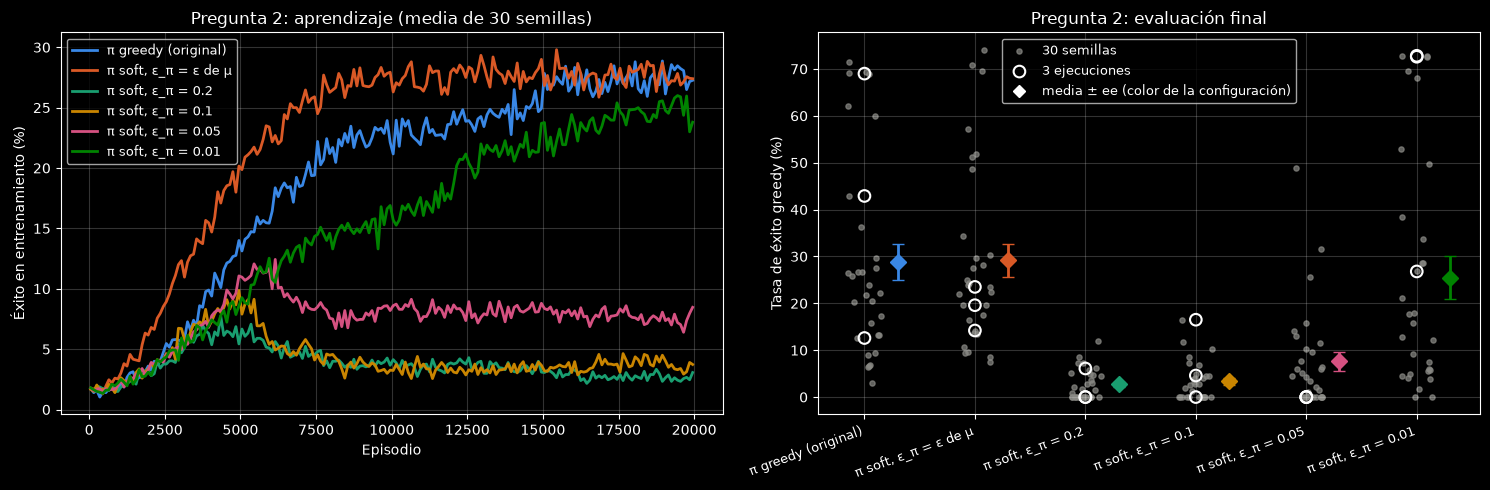

In [ ]:
# Pregunta 2: Se agrega pi_prob_soft (epsilon-greedy) y la nueva condición de corte del bucle
# Código original con π ε-greedy: pi_prob_soft reemplaza a pi_prob y el corte
# del bucle pasa a ser W < 1e-5. EPSILON_PI es el ε de π.
def entrenar_mcis_soft(semilla, NUM_EPISODES=20000, GAMMA=1.0, EPSILON_START=1.0,
                       EPSILON_END=0.01, EPSILON_DECAY=0.9995, EPSILON_PI=None):
    t0 = time.perf_counter()
    np.random.seed(semilla)
    env = gym.make('FrozenLake-v1', is_slippery=True, map_name="4x4")
    env.reset(seed=semilla)
    env.action_space.seed(semilla)

    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    C = defaultdict(lambda: np.zeros(env.action_space.n))

    def greedy_policy(s):
        return int(np.argmax(Q[s]))

    def pi_prob_soft(s, a, epsilon_pi):
        """π(a|s) ε-greedy: 1 - ε + ε/|A| para la acción greedy, ε/|A| para el resto."""
        nA = env.action_space.n
        if a == greedy_policy(s):
            return 1.0 - epsilon_pi + epsilon_pi / nA
        else:
            return epsilon_pi / nA

    def mu_prob(s, a, epsilon):
        """Política de comportamiento (ε-greedy)"""
        nA = env.action_space.n
        if a == greedy_policy(s):
            return 1.0 - epsilon + epsilon / nA
        else:
            return epsilon / nA

    def generate_episode(epsilon):
        episode = []
        state, _ = env.reset()
        while True:
            if np.random.rand() < epsilon:
                action = env.action_space.sample()
            else:
                action = greedy_policy(state)

            next_state, reward, terminated, truncated, _ = env.step(action)
            episode.append((state, action, reward))

            if terminated or truncated:
                break
            state = next_state
        return episode

    rewards_per_episode = []
    epsilon = EPSILON_START
    n_updates = 0
    w_max = 1.0  # diagnóstico: mayor peso de importancia observado

    for ep in range(NUM_EPISODES):
        episode = generate_episode(epsilon)
        epsilon_pi = epsilon if EPSILON_PI is None else EPSILON_PI

        G = 0.0
        W = 1.0

        # Bucle hacia atrás
        for t in range(len(episode) - 1, -1, -1):
            St, At, Rt = episode[t]
            G = GAMMA * G + Rt

            C[St][At] += W
            Q[St][At] += (W / C[St][At]) * (G - Q[St][At])
            n_updates += 1
            W = W * (pi_prob_soft(St, At, epsilon_pi) / mu_prob(St, At, epsilon))
            w_max = max(w_max, W)

            if W < 1e-5:
                break

        rewards_per_episode.append(episode[-1][2])
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    return resultado_corrida(env, Q, C, rewards_per_episode, epsilon, n_updates, t0, w_max=w_max)


VALORES_EPSILON_PI = [None, 0.2, 0.1, 0.05, 0.01]
etiquetas_p2 = ['π greedy (original)'] + [
    'π soft, ε_π = ε de μ' if e is None else f'π soft, ε_π = {e}' for e in VALORES_EPSILON_PI]
res_p2 = [res_base] + ejecutar(entrenar_mcis_soft, [dict(EPSILON_PI=e) for e in VALORES_EPSILON_PI])
resumir(etiquetas_p2, res_p2)
print("\nPeso de importancia máximo W (mediana de 30 semillas):")
for et, res in zip(etiquetas_p2[1:], res_p2[1:]):
    print(f"  {et:<24}{np.median([r['w_max'] for r in res]):>14.3g}")
graficar(etiquetas_p2, res_p2, 'Pregunta 2')

Respuesta

Con π ε greedy (pi_prob_soft) y el corte en W < 10⁻⁵ la tasa de éxito no mejora en ninguna variante (la única ventaja es la naranja que aprende más rápido) y en la mayoría empeora mucho. Hay que decidir qué ε usa π; se probaron el mismo ε que μ y varios valores fijos.

1. Si π usa el mismo ε que μ, las dos políticas son idénticas, el cociente π/μ vale 1 en cada paso y W queda fijo en 1 (su máximo es 1). El método deja de ser off policy: es Monte Carlo on policy de cada visita con promedio simple, porque C solo cuenta visitas. Aprovecha todos los pasos de cada episodio (18.7 actualizaciones por episodio contra 10.0), pero estima el valor de la política exploratoria y no el de la greedy, y promedia retornos de todas las políticas por las que pasó desde el comienzo. Resultado: 29.2%, igual que el original (28.8%).
2. Si π tiene un ε fijo de 0.2, 0.1 o 0.05, el éxito cae a 2.7%, 3.4% y 7.6%. Al principio, con ε de μ cerca de 1, cada acción greedy multiplica W por un valor entre 3.4 y 3.85; al final, con ε de μ en 0.01, cada acción no greedy lo multiplica por ε_π / 0.01, entre 5 y 20. Como W es un producto de cocientes, crece de forma exponencial con el largo del episodio: la mediana del W máximo llega a valores entre 10¹¹ y 10²⁴. La curva de aprendizaje muestra el momento exacto: cada variante aprende igual que el original hasta que el ε de μ baja de ε_π (episodios 3218, 4604 y 5990 para 0.2, 0.1 y 0.05) y desde ahí se derrumba. El estimador ponderado es un promedio de retornos con esos pesos, así que lo deciden uno o dos episodios con el peso más grande y el resto prácticamente no cuenta. La estimación tiene una varianza enorme y la política greedy que sale de ella es casi aleatoria.
3. Con ε_π = 0.01, π es casi greedy, W crece poco y el resultado (25.5%) no se distingue del original. Con 3 ejecuciones parecía una gran mejora (57.4%).

El cambio del corte de W == 0 a W < 10⁻⁵ es necesario porque con π soft W nunca vale exactamente 0, pero casi no actúa: lo que limita a π soft no es que W se haga chico sino que se hace enorme.

Conclusión: no mejora. La ventaja de una π soft (W no se anula y se aprovechan los episodios completos) queda anulada por la varianza de los pesos de importancia o, si π copia el ε de μ, porque el método pasa a ser on policy y estima la política exploratoria.

Referencia: (Métodos de Monte Carlo, págs. 83 y 84) probabilidades de la política ε greedy, (Métodos de Monte Carlo, pág. 81) on policy y off policy y (Métodos de Monte Carlo, págs. 89 a 92) muestreo por importancia ordinario y ponderado.

**3.** ¿Qué ocurre si se reduce el valor de `EPSILON_START`? ¿Qué valor de `EPSILON_START` es más conveniente? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

180 corridas en 44 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
EPSILON_START = 1.0 (original)       69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
EPSILON_START = 0.8                  26.0%   21.5%   67.4%    38.3%     37.3% ±  4.6    14.4     0.0   26.8    29.0
EPSILON_START = 0.6                  17.6%   71.1%   73.0%    53.9%     38.9% ±  4.5    15.5     0.0   25.6    27.4
EPSILON_START = 0.4                  68.7%   59.1%   15.1%    47.6%     31.8% ±  4.4    15.6     0.3   24.4    27.0
EPSILON_START = 0.2                  73.6%    0.0%    0.0%    24.5%      7.2% ±  3.0    14.2     7.2   18.0    22.3
EPSILON_START = 0.1                  73.8%    0.0%    0.0%    24.6%      2.5% ±  2.5    15.5    15.9   18.6    36.6
EPSILON_START = 0.05                  0.0%    0.0%    0.0%     0.0%      0.0% ±  0.0    15.5    19.9   17.8     0.0


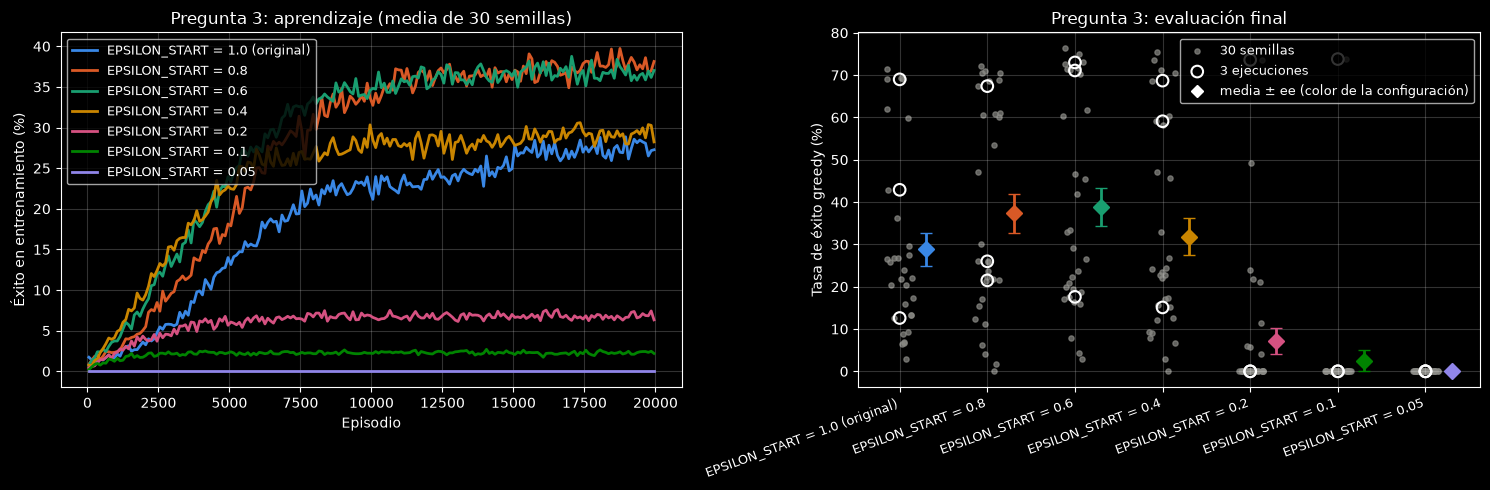


Política aprendida con EPSILON_START = 0.6 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 17.6%    ejec 2: 71.1%    ejec 3: 73.0%
→ → → ↑           ← ↓ ← ←           ← ↓ ← ←       
← H → H           ← H ← H           ← H → H       
↑ ↓ ← H           ↑ ↓ ← H           ↑ ↓ ← H       
H ↑ → G           H → ↓ G           H → ↓ G       

Política aprendida con EPSILON_START = 0.05 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1:  0.0%    ejec 2:  0.0%    ejec 3:  0.0%
← ← ← ←           ← ← ← ←           ← ← ← ←       
← H ← H           ← H ← H           ← H ← H       
← ← ← H           ← ← ← H           ← ← ← H       
H ← ← G           H ← ← G           H ← ← G       


In [ ]:
# Pregunta 3: probando distintos valores de EPSILON_START
# Se reutiliza entrenar_mcis de la pregunta 1 con Q_INIT = 0 (código original)
VALORES_EPSILON_START = [0.8, 0.6, 0.4, 0.2, 0.1, 0.05]
etiquetas_p3 = ['EPSILON_START = 1.0 (original)'] + [f'EPSILON_START = {v}' for v in VALORES_EPSILON_START]
res_p3 = [res_base] + ejecutar(entrenar_mcis, [dict(EPSILON_START=v) for v in VALORES_EPSILON_START])
resumir(etiquetas_p3, res_p3)
graficar(etiquetas_p3, res_p3, 'Pregunta 3')
mejor_p3 = int(np.argmax([exitos(r).mean() for r in res_p3]))
mostrar_politicas(res_p3[mejor_p3], f'Política aprendida con {etiquetas_p3[mejor_p3]}')
mostrar_politicas(res_p3[VALORES_EPSILON_START.index(0.05) + 1], 'Política aprendida con EPSILON_START = 0.05')

Respuesta

Bajar un poco EPSILON_START ayuda y bajarlo mucho rompe el aprendizaje. Medias en 30 semillas: 1.0 (original) 28.8%, 0.8 37.3%, 0.6 38.9%, 0.4 31.8%, 0.2 7.2%, 0.1 2.5% y 0.05 0%.

Por qué. Hay dos efectos opuestos.

1. Con menos exploración μ se parece más a π greedy: hay menos acciones no greedy que anulen W y cada episodio aporta más actualizaciones (10.0 por episodio con 1.0 contra 14.4 y 15.5 con 0.8 y 0.6). Además ε llega antes a EPSILON_END y la fase en la que se aprende de episodios casi completos es más larga.
2. Pero al comienzo Q vale 0 en todos los estados y np.argmax resuelve los empates con la acción 0, izquierda, que en FrozenLake empuja contra la pared y casi nunca lleva a la meta. Si ε arranca bajo, el agente casi no prueba otras acciones, rara vez recibe la recompensa de +1 y Q sigue en 0: queda atrapado en la política inicial. Con 0.05 las 3 ejecuciones terminan con izquierda en todos los estados, el éxito es 0% en las 30 semillas y quedan en promedio casi 20 de los 44 pares (s, a) sin actualizar.

El valor más conveniente está entre 0.6 y 0.8 (38.9% y 37.3%, unos 10 puntos más que el original, alrededor de dos errores estándar): se explora lo suficiente para descubrir la meta y se desperdician menos episodios. La mejora es moderada y solo existe en ese rango. Es el compromiso entre exploración y explotación, y la razón por la que GLIE propone explorar mucho al principio y reducir ε de forma gradual.

Referencia: (Introducción al aprendizaje por refuerzo, pág. 13) exploración y explotación, (Métodos de Monte Carlo, pág. 85) GLIE y (Métodos de Monte Carlo, pág. 53) si nunca se prueban ciertas acciones se pierde la mejor.

**4.** ¿Qué sucede si se reduce el valor de `GAMMA`? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

150 corridas en 29 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
GAMMA = 1.0 (original)               69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
GAMMA = 0.99                         23.1%    3.9%   10.3%    12.4%     29.6% ±  4.0    10.3     0.0   20.4    24.0
GAMMA = 0.95                         67.7%    3.3%   39.4%    36.8%     33.5% ±  4.6    10.8     0.0   21.8    25.0
GAMMA = 0.9                          59.2%    3.6%   25.0%    29.3%     29.2% ±  4.0    10.5     0.0   19.5    23.9
GAMMA = 0.8                          24.6%    2.9%   23.3%    16.9%     25.7% ±  3.9     9.1     0.0   18.7    23.2
GAMMA = 0.6                          19.6%    0.0%   35.6%    18.4%     21.9% ±  3.0     8.1     0.0   16.7    21.4


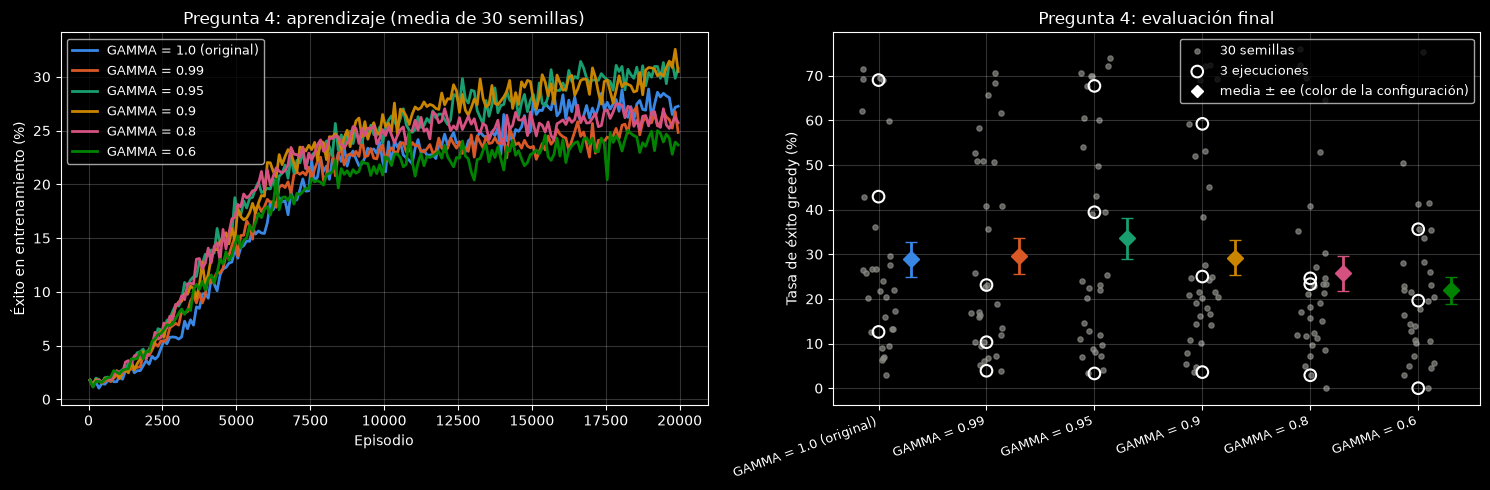


Política aprendida con GAMMA = 1.0 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 69.0%    ejec 2: 12.6%    ejec 3: 42.9%
← ← ↑ ↓           ↑ ↑ → ↓           → ↑ ↓ ←       
← H → H           ← H → H           ← H ← H       
↑ ↓ ← H           → ↓ ← H           ↑ ↓ ← H       
H → ↓ G           H → ↓ G           H → ↓ G       

Política aprendida con GAMMA = 0.6 (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 19.6%    ejec 2:  0.0%    ejec 3: 35.6%
← ↓ → ↓           ↑ ← → ↓           → ↑ ↓ ←       
← H → H           → H ← H           ← H ↓ H       
↓ → ← H           ↑ ↓ ← H           ↑ ↓ ← H       
H → ↓ G           H → ↓ G           H → ↓ G       

Política óptima para cada GAMMA, evaluada en 10000 episodios (← 0, ↓ 1, → 2, ↑ 3):


  GAMMA = 1.0   éxito  74.8%   pasos a la meta  38.6   ←↑↑↑ / ←H←H / ↑↓←H / H→↓G


  GAMMA = 0.99  éxito  74.8%   pasos a la meta  38.6   ←↑↑↑ / ←H←H / ↑↓←H / H→↓G


  GAMMA = 0.95  éxito  73.6%   pasos a la meta  37.4   ←↑←↑ / ←H←H / ↑↓←H / H→↓G


  GAMMA = 0.9   éxito  73.6%   pasos a la meta  37.4   ←↑←↑ / ←H←H / ↑↓←H / H→↓G


  GAMMA = 0.8   éxito  44.5%   pasos a la meta  28.4   ↓↑→↑ / ←H←H / ↑↓←H / H→↓G


  GAMMA = 0.6   éxito  44.5%   pasos a la meta  28.4   ↓↑→↑ / ←H←H / ↑↓←H / H→↓G


In [ ]:
# Pregunta 4: probando distintos valores de GAMMA
# Se reutiliza entrenar_mcis con Q_INIT = 0.
VALORES_GAMMA = [0.99, 0.95, 0.9, 0.8, 0.6]
etiquetas_p4 = ['GAMMA = 1.0 (original)'] + [f'GAMMA = {v}' for v in VALORES_GAMMA]
res_p4 = [res_base] + ejecutar(entrenar_mcis, [dict(GAMMA=v) for v in VALORES_GAMMA])
resumir(etiquetas_p4, res_p4)
graficar(etiquetas_p4, res_p4, 'Pregunta 4')
mostrar_politicas(res_base, 'Política aprendida con GAMMA = 1.0')
mostrar_politicas(res_p4[VALORES_GAMMA.index(0.6) + 1], 'Política aprendida con GAMMA = 0.6')

# Referencia: qué hace la política óptima de cada GAMMA (calculada con el modelo)
print("\nPolítica óptima para cada GAMMA, evaluada en 10000 episodios (← 0, ↓ 1, → 2, ↑ 3):")
for g in [1.0] + VALORES_GAMMA:
    pol = politica_optima(g, env_ref)
    exito, _, pasos = evaluar_politica_fija(env_ref, pol)
    filas = ' / '.join(''.join(MAPA[f][c] if MAPA[f][c] in 'HG' else ARROWS[pol[f * 4 + c]]
                               for c in range(4)) for f in range(4))
    print(f"  GAMMA = {g:<5} éxito {100 * exito:5.1f}%   pasos a la meta {pasos:5.1f}   {filas}")

Respuesta

Reducir GAMMA no mejora la tasa de éxito. Medias en 30 semillas: 1.0 (original) 28.8%, 0.99 29.6%, 0.95 33.5%, 0.9 29.2%, 0.8 25.7% y 0.6 21.9%. Ninguna diferencia supera el error estándar (unos 4 puntos) lo suficiente para hablar de una mejora, y la tendencia con γ bajo es a empeorar (21.9% con 0.6).

Por qué. En FrozenLake la única recompensa es +1 al llegar a la meta, así que con γ < 1 el retorno de un episodio exitoso vale γ elevado a la cantidad de pasos que faltaban. γ no cambia qué episodios terminan bien: solo hace que llegar tarde valga menos que llegar pronto. Como el hielo es resbaladizo, los caminos seguros son largos (avanzan empujando contra las paredes para que un resbalón no los tire a un agujero) y los cortos pasan junto a los agujeros. Con γ chico conviene el camino corto y riesgoso. Se ve sin el ruido del aprendizaje en la política óptima de cada γ, calculada con el modelo del entorno solo como referencia: con γ entre 0.9 y 1 llega a la meta en el 73.6% a 74.8% de los episodios, en unos 38 pasos; con γ = 0.8 o 0.6 cambia la acción del estado inicial (abajo en lugar de izquierda) y la del estado 2 (derecha en lugar de arriba), llega en unos 28 pasos y solo en el 44.5% de los episodios. Es decir, con γ bajo la política óptima del problema descontado deja de ser la que más veces llega a la meta. En el agente MCIS el mismo efecto se mezcla con el ruido del aprendizaje: los episodios exitosos de la evaluación tardan 25.0 pasos de media con γ = 1 y 21.4 con γ = 0.6. Con γ cercano a 1 el efecto es casi nulo.

Además el descuento hace falta en tareas continuas o de horizonte infinito, para que la suma de recompensas sea finita. FrozenLake es episódica: termina en un agujero, en la meta o a los 100 pasos, así que γ = 1 es válido y es el que corresponde a lo que se evalúa, la probabilidad de llegar a la meta. Conviene dejar GAMMA = 1.

Referencia: (Proceso de decisión de Markov, pág. 34) FrozenLake como tarea episódica, (Proceso de decisión de Markov, págs. 36 a 39) descuento y horizonte, (Métodos de diferencia temporal, pág. 34) recompensas de FrozenLake y (Programación dinámica, págs. 71 a 73) iteración de valor, usada para la política óptima de referencia.

**5.** ¿Qué ocurre si se aumenta la cantidad de episodios? (VALOR EJERCICIO 0.4)

90 corridas en 170 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
NUM_EPISODES = 20000 (original)      69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
NUM_EPISODES = 50000                 68.3%   13.3%   41.3%    41.0%     34.1% ±  4.2    13.3     0.0   23.7    26.3
NUM_EPISODES = 100000                70.8%   24.9%   49.8%    48.5%     34.9% ±  4.1    15.4     0.0   24.5    27.7
NUM_EPISODES = 200000                69.1%   25.4%   48.8%    47.8%     45.1% ±  4.2    18.0     0.0   29.9    31.3


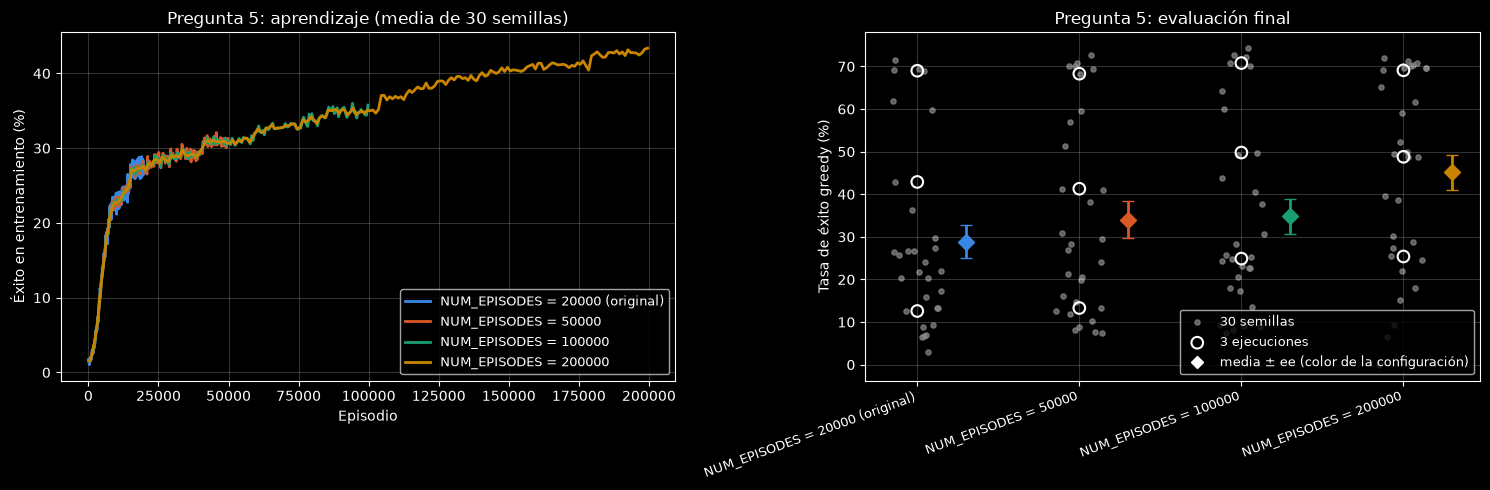


Episodio en que ε llega a EPSILON_END con EPSILON_DECAY = 0.9995: 9209


In [ ]:
# Pregunta 5: aumentando la cantidad de episodios (NUM_EPISODES)
# Se reutiliza entrenar_mcis con Q_INIT = 0.
VALORES_NUM_EPISODES = [50000, 100000, 200000]
etiquetas_p5 = ['NUM_EPISODES = 20000 (original)'] + [f'NUM_EPISODES = {v}' for v in VALORES_NUM_EPISODES]
res_p5 = [res_base] + ejecutar(entrenar_mcis, [dict(NUM_EPISODES=v) for v in VALORES_NUM_EPISODES])
resumir(etiquetas_p5, res_p5)
graficar(etiquetas_p5, res_p5, 'Pregunta 5')
print(f"\nEpisodio en que ε llega a EPSILON_END con EPSILON_DECAY = 0.9995: "
      f"{int(np.ceil(np.log(0.01) / np.log(0.9995)))}")

Respuesta

Aumentar la cantidad de episodios mejora la tasa de éxito, pero despacio. Medias en 30 semillas: 20000 (original) 28.8%, 50000 34.1%, 100000 34.9% y 200000 45.1%. Recién con 10 veces más episodios la mejora supera con claridad el error estándar.

Por qué. Con EPSILON_DECAY = 0.9995, ε llega a EPSILON_END = 0.01 en el episodio 9209, así que todo lo que se agrega es entrenamiento con 1% de exploración. En esa fase μ casi coincide con π greedy, W rara vez se anula y cada episodio aporta más actualizaciones (de 10.0 por episodio con 20000 episodios a 18.0 con 200000): el valor de llegar a la meta se propaga hacia los estados del comienzo y la política sigue mejorando, como muestra la curva de aprendizaje, que no se aplana. La mejora es lenta por dos motivos. Con ε = 0.01 casi no se prueban acciones nuevas. Y en el promedio ponderado el paso W/C se achica a medida que C acumula pesos, de modo que cada episodio nuevo pesa cada vez menos frente a los retornos acumulados desde el comienzo, que vienen de políticas anteriores y peores.

Más episodios dan estimaciones más precisas, como dice la ley de los grandes números, pero no garantizan que cada corrida llegue a una buena política: la dispersión entre semillas sigue siendo grande. La pregunta 7 extiende este análisis hasta 700000 episodios.

Referencia: (Métodos de Monte Carlo, pág. 31) más visitas dan más precisión, (Métodos de Monte Carlo, pág. 85) GLIE y (Métodos de Monte Carlo, pág. 92) promedio ponderado.

**6.** ¿Qué ocurre si se reduce la tasa de decaimiento de ε (`EPSILON_DECAY`) para prolongar la fase de exploración? ¿Mejora la tasa de éxito? (VALOR EJERCICIO 0.4)

150 corridas en 18 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
EPSILON_DECAY = 0.9995 (original)    69.0%   12.6%   42.9%    41.5%     28.8% ±  3.9    10.0     0.0   21.6    25.0
EPSILON_DECAY = 0.9997               15.8%   50.7%    7.9%    24.8%     24.4% ±  4.1     7.7     0.0   18.3    22.7
EPSILON_DECAY = 0.9998                0.0%   16.6%    0.0%     5.5%     26.2% ±  4.2     5.3     0.0   20.6    24.9
EPSILON_DECAY = 0.9999               10.3%    0.0%   20.3%    10.2%     20.4% ±  4.1     2.6     0.0   17.3    21.6
EPSILON_DECAY = 0.99995              60.7%    0.0%    8.7%    23.1%     12.7% ±  2.9     1.9     0.0   15.9    19.4
EPSILON_DECAY = 0.99999               0.0%    0.0%    0.0%     0.0%      6.8% ±  2.0     1.4     0.0   11.1    16.8

ε al final del entrenamiento y episodio en que llega a EPSILON_END:
  EPSILON_DECAY = 0.9995   ε final = 0.010   llega en el episodio 9209
  EPSILON_D

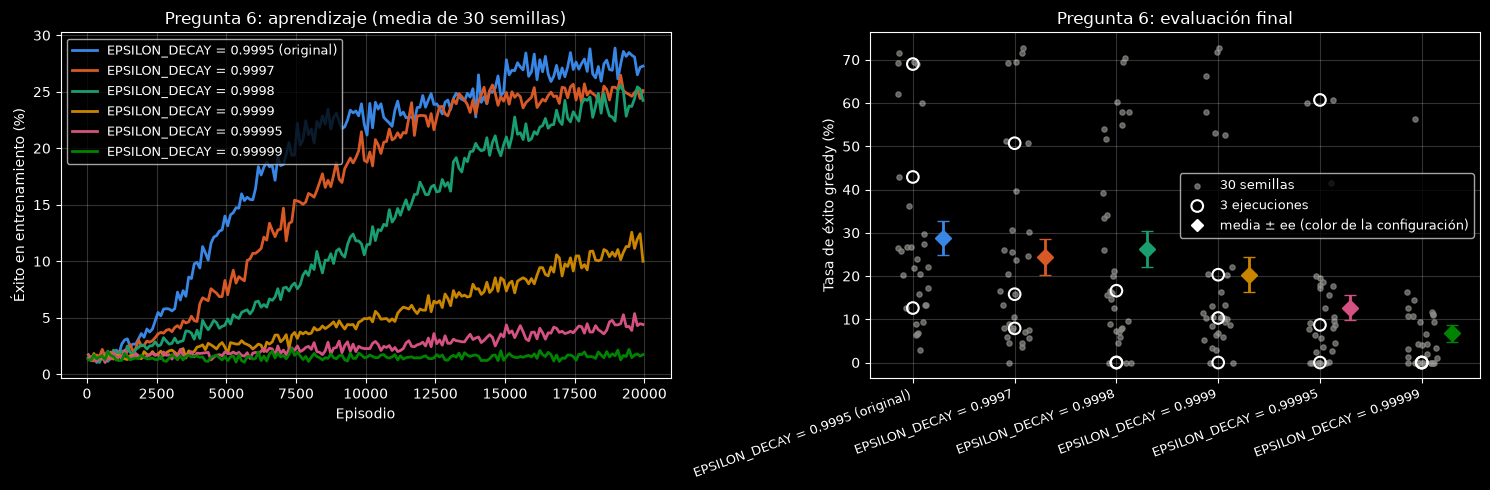

In [ ]:
# Pregunta 6: reduciendo la tasa de decaimiento de epsilon (EPSILON_DECAY)
# Se reutiliza entrenar_mcis con Q_INIT = 0.
VALORES_EPSILON_DECAY = [0.9997, 0.9998, 0.9999, 0.99995, 0.99999]
etiquetas_p6 = ['EPSILON_DECAY = 0.9995 (original)'] + [f'EPSILON_DECAY = {v}' for v in VALORES_EPSILON_DECAY]
res_p6 = [res_base] + ejecutar(entrenar_mcis, [dict(EPSILON_DECAY=v) for v in VALORES_EPSILON_DECAY])
resumir(etiquetas_p6, res_p6)
print("\nε al final del entrenamiento y episodio en que llega a EPSILON_END:")
for v in [0.9995] + VALORES_EPSILON_DECAY:
    llega = int(np.ceil(np.log(0.01) / np.log(v)))
    print(f"  EPSILON_DECAY = {v:<8} ε final = {max(0.01, v ** 20000):.3f}   llega en el episodio {llega}")
graficar(etiquetas_p6, res_p6, 'Pregunta 6')

Respuesta

No mejora: prolongar la exploración empeora la tasa de éxito, y cuanto más lento es el decaimiento, peor. Medias en 30 semillas con 20000 episodios: 0.9995 (original) 28.8%, 0.9997 24.4%, 0.9998 26.2%, 0.9999 20.4%, 0.99995 12.7% y 0.99999 6.8%. Con 0.9999 o más, ε ni siquiera llega a EPSILON_END: termina en 0.135, 0.368 y 0.819.

Por qué. La política objetivo π es greedy, así que al recorrer el episodio hacia atrás W se anula en la primera acción no greedy. Mientras ε es alto, casi todos los episodios tienen alguna acción exploratoria cerca del final y solo se aprovechan los últimos pasos: las actualizaciones por episodio bajan de 10.0 con el decaimiento original a 2.6 con 0.9999 y a 1.4 con 0.99999. El valor de llegar a la meta casi no se propaga hacia los estados del comienzo y la política greedy queda mal definida justo donde empieza cada episodio. Explorar más genera datos sobre más pares (s, a), pero el muestreo por importancia con π greedy descarta casi todos. Es la limitación conocida del control Monte Carlo off policy con π greedy: aprende solo de las colas de los episodios, y si las acciones no greedy son frecuentes el aprendizaje es lento, sobre todo para los estados del principio.

La reducción gradual de ε que propone GLIE sigue siendo necesaria, como mostró la pregunta 3, pero en este algoritmo explorar tiene un costo extra y conviene que ε baje rápido: con 20000 episodios el valor original, 0.9995, es el mejor de los probados.

Referencia: (Métodos de Monte Carlo, pág. 85) GLIE, (Métodos de Monte Carlo, pág. 92) W se multiplica por π/μ y se anula con una acción que π no tomaría y las notas de del ejemplo rl1_mc_offpolicy_gridworld_2x3_ejemplo_diapositivas.ipynb.

**7.** ¿Qué valor conviene darle a la tasa de decaimiento si se aumenta la cantidad de episodios a:

- 60000
- 100000
- 300000
- 500000
- 700000

¿Mejora, empeora o se mantiene aproximadamente igual la tasa de éxito? (VALOR EJERCICIO 0.9)

600 corridas en 2612 s con 32 procesos

configuración                       ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee  act/ep sin act  largo  a meta
N=60000, fijo 0.999                   5.7%   61.4%   72.0%    46.4%     35.9% ±  5.1    14.8     0.0   24.1    26.6
N=60000, fijo 0.9995 (original)      68.5%   26.2%   41.0%    45.2%     34.0% ±  4.2    13.8     0.0   24.1    27.1
N=60000, fijo 0.9999                 24.4%    0.0%   21.8%    15.4%     25.8% ±  4.4     7.9     0.0   19.5    24.6
N=60000, escalado a N/2              70.9%   31.6%   20.5%    41.0%     26.3% ±  4.2     9.7     0.0   18.4    23.2
N=100000, fijo 0.999                  6.9%   59.4%   72.2%    46.2%     42.8% ±  4.9    16.9     0.0   27.1    28.4
N=100000, fijo 0.9995 (original)     70.8%   24.9%   49.8%    48.5%     34.9% ±  4.1    15.4     0.0   24.5    27.7
N=100000, fijo 0.9999                24.2%    0.0%   21.5%    15.2%     25.7% ±  4.2    10.2     0.0   19.0    23.8
N=100000, escalado a N/2         

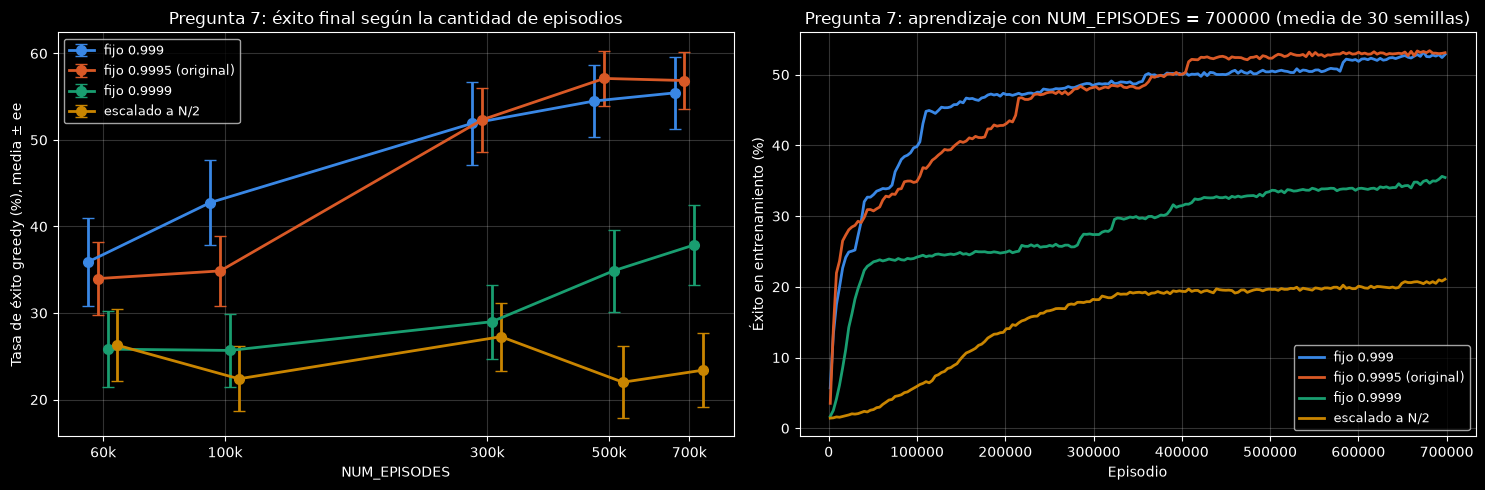


Política aprendida con N=500000, fijo 0.9995 (original) (← 0, ↓ 1, → 2, ↑ 3)
ejec 1: 67.8%    ejec 2: 30.8%    ejec 3: 51.3%
← ← ↑ ↓           ↑ ↑ → ↑           → ↑ ← ←       
← H → H           ← H → H           ← H ← H       
↑ ↓ ← H           ↑ ↓ ← H           ↑ ↓ ← H       
H → ↓ G           H → ↓ G           H → ↓ G       


In [ ]:
# Pregunta 7: probando distintas combinaciones de NUM_EPISODES y EPSILON_DECAY
# Se reutiliza entrenar_mcis con Q_INIT = 0.
# Se comparan decaimientos fijos con uno escalado para que ε llegue a EPSILON_END a la mitad del entrenamiento, sea cual sea la cantidad de episodios.
VALORES_N = [60000, 100000, 300000, 500000, 700000]


def decay_escalado(n, fraccion=0.5, eps_start=1.0, eps_end=0.01):
    """EPSILON_DECAY tal que ε pasa de eps_start a eps_end en fraccion * n episodios."""
    return (eps_end / eps_start) ** (1 / (fraccion * n))


ESTRATEGIAS = {
    'fijo 0.999': lambda n: 0.999,
    'fijo 0.9995 (original)': lambda n: 0.9995,
    'fijo 0.9999': lambda n: 0.9999,
    'escalado a N/2': decay_escalado,
}
NOMBRES = list(ESTRATEGIAS)
K = len(ESTRATEGIAS)
configs_p7 = [dict(NUM_EPISODES=n, EPSILON_DECAY=f(n)) for n in VALORES_N for f in ESTRATEGIAS.values()]
etiquetas_p7 = [f"N={n}, {nombre}" for n in VALORES_N for nombre in NOMBRES]
res_p7 = ejecutar(entrenar_mcis, configs_p7)
resumir(etiquetas_p7, res_p7)

print("\nEPSILON_DECAY escalado a N/2 y episodio en que ε llega a EPSILON_END:")
for n in VALORES_N:
    print(f"  N = {n:>6}: EPSILON_DECAY = {decay_escalado(n):.7f}, llega en el episodio {n // 2}")

print("\nEstrategia con mayor éxito medio para cada N:")
for i, n in enumerate(VALORES_N):
    medias = [exitos(r).mean() for r in res_p7[i * K:(i + 1) * K]]
    j = int(np.argmax(medias))
    print(f"  N = {n:>6}: {NOMBRES[j]:<24} EPSILON_DECAY = {configs_p7[i * K + j]['EPSILON_DECAY']:.7f}"
          f"   éxito medio {100 * medias[j]:.1f}%")

# Izquierda: éxito greedy en función de N. Derecha: aprendizaje con el N más grande.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for j, nombre in enumerate(NOMBRES):
    res_j = [res_p7[i * K + j] for i in range(len(VALORES_N))]
    medias = [100 * exitos(r).mean() for r in res_j]
    ees = [100 * exitos(r).std(ddof=1) / np.sqrt(len(r)) for r in res_j]
    x = np.array(VALORES_N) * (1 + 0.04 * (j - (K - 1) / 2))  # desplazamiento para no superponer
    ax1.errorbar(x, medias, yerr=ees, color=COLORES[j], marker='o', markersize=7,
                 linewidth=2, capsize=4, label=nombre)
    r_ult = res_j[-1]
    xc = (np.arange(N_PUNTOS_CURVA) + 0.5) * r_ult[0]['num_episodes'] / N_PUNTOS_CURVA
    ax2.plot(xc, 100 * np.mean([r['curva'] for r in r_ult], axis=0), color=COLORES[j],
             linewidth=2, label=nombre)
ax1.set_xscale('log')
ax1.set_xticks(VALORES_N, [f'{n // 1000}k' for n in VALORES_N])
ax1.minorticks_off()
ax1.set_xlabel('NUM_EPISODES'); ax1.set_ylabel('Tasa de éxito greedy (%), media ± ee')
ax1.set_title('Pregunta 7: éxito final según la cantidad de episodios')
ax1.legend(fontsize=9); ax1.grid(alpha=0.2)
ax2.set_xlabel('Episodio'); ax2.set_ylabel('Éxito en entrenamiento (%)')
ax2.set_title(f'Pregunta 7: aprendizaje con NUM_EPISODES = {VALORES_N[-1]} (media de {len(SEMILLAS)} semillas)')
ax2.legend(fontsize=9); ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()
mejor = max(range(len(res_p7)), key=lambda i: exitos(res_p7[i]).mean())
mostrar_politicas(res_p7[mejor], f'Política aprendida con {etiquetas_p7[mejor]}')

Respuesta

El decaimiento conveniente no se escala con la cantidad de episodios: lo que funciona es un decaimiento rápido, entre 0.999 y 0.9995, que lleve ε a EPSILON_END en los primeros 5000 a 10000 episodios, sea cual sea NUM_EPISODES. Para cada cantidad de episodios se compararon cuatro estrategias: dos decaimientos fijos rápidos (0.999 y el original, 0.9995), uno fijo más lento (0.9999) y uno escalado para que ε llegue a su mínimo a la mitad del entrenamiento, que es la regla que surge naturalmente al aumentar los episodios (0.9998465 para 60000, 0.9999079 para 100000, 0.9999693 para 300000, 0.9999816 para 500000 y 0.9999868 para 700000).

Valor recomendado y tasa de éxito media en 30 semillas (entre los dos decaimientos rápidos la diferencia está dentro del error estadístico, así que cualquiera de los dos sirve):

1. 60000 episodios: 0.999, 35.9% (0.9995 da 34.0%).
2. 100000 episodios: 0.999, 42.8% (0.9995 da 34.9%).
3. 300000 episodios: 0.9995, 52.3% (0.999 da 51.9%).
4. 500000 episodios: 0.9995, 57.1% (0.999 da 54.5%).
5. 700000 episodios: 0.9995, 56.9% (0.999 da 55.4%).

¿Mejora, empeora o se mantiene? Con un decaimiento rápido la tasa de éxito mejora al aumentar los episodios, de 28.8% con 20000 a alrededor de 52% con 300000, y desde 500000 se mantiene aproximadamente igual (57.1% y 56.9% con 500000 y 700000). Sigue lejos del 74.8% de la política óptima porque con ε = 0.01 se prueban pocas acciones nuevas y varias corridas quedan atrapadas en políticas peores: con 700000 episodios las 3 ejecuciones dan 71.2%, 29.2% y 50.6%. Con el decaimiento fijo 0.9999 también mejora con N, pero siempre por debajo (de 25.8% a 37.9%). Con el decaimiento escalado empeora: queda entre 22% y 27% con cualquier cantidad de episodios, por debajo del código original con 20000.

Por qué. Valen las dos razones de las preguntas 5 y 6. Mientras ε es alto, la política greedy corta W en casi todos los episodios y se aprende solo de los últimos pasos; recién con ε chico cada episodio aporta muchas actualizaciones (con 700000 episodios, 23.4 por episodio con los decaimientos rápidos contra 8.7 con el escalado). Y el promedio ponderado tiene memoria: C acumula los pesos desde el comienzo, así que si la fase exploratoria dura cientos de miles de episodios, los retornos de esa fase, generados por políticas malas, dominan C y los episodios posteriores casi no mueven Q. Se ve en la curva de aprendizaje con 700000 episodios: el decaimiento escalado llega al ε mínimo en el episodio 350000, pero su éxito queda estancado cerca de 20% hasta el final.

La regla práctica es la opuesta a la intuición: con más episodios no conviene explorar durante más tiempo, sino dedicar el tiempo extra a la fase de explotación. La reducción de ε hacia su mínimo que pide GLIE se cumple igual; lo que cambia es que en MCIS con π greedy conviene hacerla rápido.

Referencia: (Métodos de Monte Carlo, pág. 85) (GLIE), (Métodos de Monte Carlo, pág. 92) promedio ponderado con C y W.

## Conclusiones

1. Lo que más pesa en todos los resultados es que π sea greedy: W se anula en la primera acción exploratoria contada desde el final del episodio, así que el algoritmo aprende solo de las colas de los episodios. Todo lo que hace coincidir a μ con π (ε que baja rápido, un ε inicial algo menor, valores iniciales optimistas que hacen explorar a la propia política greedy) aumenta las actualizaciones por episodio y mejora el resultado; todo lo que prolonga la exploración lo empeora.
2. Explorar sigue siendo imprescindible: con un ε inicial muy bajo el agente se queda con la política inicial, siempre a la izquierda, y nunca encuentra la meta.
3. Hacer soft a π evita que W se anule, pero los pesos de importancia crecen sin control y el estimador ponderado queda en manos de pocos episodios; si π usa el mismo ε que μ, el método se vuelve on policy y no mejora.
4. Un GAMMA menor que 1 no ayuda en una tarea episódica cuyo objetivo es llegar a la meta: favorece caminos cortos y riesgosos.
5. Más episodios mejoran el resultado siempre que ε llegue pronto a su mínimo; escalar el decaimiento con la cantidad de episodios lo empeora.
6. La variabilidad entre corridas con la misma configuración es enorme, por eso las conclusiones se apoyan en 30 semillas y no solo en las 3 ejecuciones pedidas.